In [66]:
# Command to install all packages
# pip install numpy pandas matplotlib seaborn scikit-learn openpyxl geopandas shapely pyogrio folium branca jupyterlab ipykernel requests

---
## 1.Package Imports

In [67]:
from pathlib import Path
import re
import unicodedata
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import OPTICS, SpectralClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

import geopandas as gpd
from matplotlib.patches import Patch
import requests, io

---
## 2.Configruation

In [68]:
PROJECT_DIR = Path.cwd()
DATA_FILE = "Data Indeks Masyarakat Digital Indonesia Kab_Kota 2025.xlsx"
GEOJSON_URL = "https://raw.githubusercontent.com/AlfianAliM/Indonesia-GeoJSON/master/kab_kota.geojson"
OUTPUT_DIR = PROJECT_DIR / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
IQR_MULTIPLIER = 1.5

# OPTICS_MIN_SAMPLES_LIST = [10, 20, 30, 40, 50]
OPTICS_MIN_SAMPLES_LIST = [5, 10, 15, 20, 25]
SPECTRAL_K_LIST = list(range(2, 11))

# Konfigurasi terbaik untuk visualisasi akhir setiap model.
best_optics_min_samples = 5
best_spectral_k = 2

# Parameter OPTICS tetap untuk seluruh eksperimen.
OPTICS_FIXED_PARAMS = {
    "max_eps": np.inf,
    "metric": "minkowski",
    "p": 2,
    "cluster_method": "xi",
    "xi": 0.05,
    "min_cluster_size": 10,
}

# Parameter Spectral Clustering tetap untuk seluruh eksperimen.
SPECTRAL_FIXED_PARAMS = {
    "affinity": "nearest_neighbors",
    "n_neighbors": 10,
    "assign_labels": "kmeans",
    "n_init": 20,
    "random_state": RANDOM_STATE,
}

# Enam subpilar IMDI yang digunakan sebagai fitur clustering.
SUBPILAR_FEATURES = [
    "Akses dan Adopsi Teknologi Digital",
    "Literasi Digital Dasar",
    "Ritel/E-Commerce",
]

METADATA_COLUMNS = [
    "Tahun", "Kode Provinsi", "Provinsi", "Kode Kabupaten/Kota", "Kabupaten/Kota"
]
INDEX_COLUMN = "Indeks Masyarakat Digital"

print("Folder proyek :", PROJECT_DIR)
print("Folder output :", OUTPUT_DIR)
print("GeoJSON       :", GEOJSON_URL)
print("Jumlah fitur clustering:", len(SUBPILAR_FEATURES))


Folder proyek : c:\Users\Valentino\OneDrive - Universitas Tarumanagara\Documents\Kuliah\Semester 7\Machine Learning\Tugas\UAS\Project
Folder output : c:\Users\Valentino\OneDrive - Universitas Tarumanagara\Documents\Kuliah\Semester 7\Machine Learning\Tugas\UAS\Project\outputs
GeoJSON       : https://raw.githubusercontent.com/AlfianAliM/Indonesia-GeoJSON/master/kab_kota.geojson
Jumlah fitur clustering: 3


---
## 3.Dataset Loading and Cleaning

In [69]:
data_path = PROJECT_DIR / DATA_FILE
if not data_path.exists():
    candidates = sorted(PROJECT_DIR.glob("Data Indeks Masyarakat Digital Indonesia Kab_Kota 2025*.xlsx"))
    if len(candidates) == 1:
        data_path = candidates[0]
    elif len(candidates) > 1:
        raise FileNotFoundError(
            "Ditemukan lebih dari satu file dataset. Tetapkan DATA_FILE secara manual: "
            + ", ".join(p.name for p in candidates)
        )
    else:
        raise FileNotFoundError(
            f"File Excel tidak ditemukan: {data_path}\n"
            "Letakkan file Excel berdampingan dengan notebook atau ubah DATA_FILE."
        )

raw = pd.read_excel(data_path, header=[0, 1], engine="openpyxl")

def clean_header(value):
    text = str(value).replace("\n", " ")
    text = re.sub(r"\s+", " ", text).strip()
    return text

flat_columns = []
for idx, col in enumerate(raw.columns):
    first = clean_header(col[0])
    second = clean_header(col[1])
    if idx >= 10 and second.lower().startswith("subpilar "):
        flat_columns.append(second[len("Subpilar "):].strip())
    else:
        flat_columns.append(first)

if len(flat_columns) != len(set(flat_columns)):
    raise ValueError("Header setelah diratakan tidak unik. Periksa struktur file Excel.")

df = raw.copy()
df.columns = flat_columns

required_columns = METADATA_COLUMNS + [INDEX_COLUMN] + SUBPILAR_FEATURES
missing_columns = [col for col in required_columns if col not in df.columns]
if missing_columns:
    raise KeyError(f"Kolom wajib tidak ditemukan: {missing_columns}\nKolom tersedia: {df.columns.tolist()}")

print(f"File dibaca: {data_path.name}")
print("Ukuran dataset:", df.shape)
display(df.head())

File dibaca: Data Indeks Masyarakat Digital Indonesia Kab_Kota 2025.xlsx
Ukuran dataset: (514, 21)


,Tahun,Kode Provinsi,Provinsi,Kode Kabupaten/Kota,Kabupaten/Kota,Indeks Masyarakat Digital,Pilar Infrastruktur dan Ekosistem,Pilar Keterampilan Digital,Pilar Pemberdayaan,Pilar Pekerjaan,...,Ekosistem Pembelajaran,Digitalisasi Pemerintah,Literasi Digital Dasar,Keamanan Digital,Etika Digital,Ritel/E-Commerce,Keuangan Digital,Layanan dan Kreasi Produk Digital,Permintaan,Penawaran
0,2025,32,JAWA BARAT,71,KOTA BANDUNG,64.767412,89.9079,65.667538,53.394144,48.65990,...,99.1702,96.2264,71.9677,56.5914,98.2258,69.8871,60.7419,27.7078,52.7918,44.5280
1,2025,35,JAWA TIMUR,7,KOTA MALANG,62.670962,79.6064,63.693764,57.731727,46.55215,...,75.0708,88.8889,67.2578,57.3750,95.8750,70.3750,61.1875,40.3846,47.4990,45.6053
2,2025,82,DKI JAKARTA,74,KOTA JAKARTA BARAT,61.581305,77.4086,61.963466,57.883132,45.85115,...,67.5649,93.5010,65.7625,55.1750,96.8833,67.6500,74.1875,29.8033,50.2480,41.4543
3,2025,12,SUMATERA UTARA,75,KOTA MEDAN,59.996021,79.6990,52.387428,59.636804,45.77850,...,90.5709,76.9392,55.6802,45.3411,96.1628,65.5465,73.9767,37.8291,48.5769,42.9801
4,2025,82,DKI JAKARTA,71,KOTA JAKARTA SELATAN,59.925852,83.4267,50.996545,57.922279,45.41470,...,86.9249,93.5010,54.7014,43.3704,96.7407,73.6389,66.5139,31.7335,52.7069,38.1225


---
## 4.Data Pre-Processing

In [70]:
print("Jumlah baris:", len(df))
print("Jumlah kolom:", df.shape[1])
print("Jumlah provinsi unik:", df["Provinsi"].nunique())
print("Jumlah kabupaten/kota unik:", df[["Provinsi", "Kabupaten/Kota"]].drop_duplicates().shape[0])
print("Duplikasi seluruh baris:", df.duplicated().sum())
print("Duplikasi kunci Provinsi + Kabupaten/Kota:", df.duplicated(["Provinsi", "Kabupaten/Kota"]).sum())

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(3),
})
display(missing_summary)

province_code_conflicts = (
    df[["Kode Provinsi", "Provinsi"]]
    .drop_duplicates()
    .groupby("Kode Provinsi")["Provinsi"]
    .nunique()
)
province_code_conflicts = province_code_conflicts[province_code_conflicts > 1]
if not province_code_conflicts.empty:
    print("PERINGATAN: ada Kode Provinsi yang terhubung dengan lebih dari satu nama provinsi:")
    display(province_code_conflicts.rename("jumlah_nama_provinsi").to_frame())
    print("Kode administratif tidak digunakan untuk clustering maupun join peta.")

X_raw = df[SUBPILAR_FEATURES].apply(pd.to_numeric, errors="coerce")
if X_raw.isna().any().any():
    raise ValueError("Ada nilai kosong/non-numerik pada fitur subpilar. Periksa file sumber sebelum pemodelan.")

if df["Provinsi"].isna().any() or df["Kabupaten/Kota"].isna().any():
    raise ValueError("Kolom identitas Provinsi/Kabupaten/Kota memiliki nilai kosong.")

print("\nRingkasan statistik enam fitur subpilar terpilih:")
display(X_raw.describe().T.round(3))

out_of_range = ((X_raw < 1) | (X_raw > 100)).sum()
if (out_of_range > 0).any():
    print("PERINGATAN: ditemukan nilai subpilar di luar rentang 1–100:")
    display(out_of_range[out_of_range > 0].rename("jumlah").to_frame())
else:
    print("Semua nilai fitur terpilih berada dalam rentang 1–100.")

if df.isna().sum().sum() > 0:
    raise ValueError(
        "Dataset memiliki missing value. Notebook menghentikan proses agar strategi imputasi "
    )

Jumlah baris: 514
Jumlah kolom: 21
Jumlah provinsi unik: 38
Jumlah kabupaten/kota unik: 514
Duplikasi seluruh baris: 0
Duplikasi kunci Provinsi + Kabupaten/Kota: 0


,missing_count,missing_percent
Tahun,0,0.0
Kode Provinsi,0,0.0
Provinsi,0,0.0
Kode Kabupaten/Kota,0,0.0
Kabupaten/Kota,0,0.0
Indeks Masyarakat Digital,0,0.0
Pilar Infrastruktur dan Ekosistem,0,0.0
Pilar Keterampilan Digital,0,0.0
Pilar Pemberdayaan,0,0.0
Pilar Pekerjaan,0,0.0


PERINGATAN: ada Kode Provinsi yang terhubung dengan lebih dari satu nama provinsi:


,jumlah_nama_provinsi
Kode Provinsi,
11,2
82,2


Kode administratif tidak digunakan untuk clustering maupun join peta.

Ringkasan statistik enam fitur subpilar terpilih:


,count,mean,std,min,25%,50%,75%,max
Akses dan Adopsi Teknologi Digital,514.0,59.342,11.115,17.727,52.732,61.028,67.687,89.342
Literasi Digital Dasar,514.0,54.561,10.977,14.569,47.925,54.663,61.930,84.926
Ritel/E-Commerce,514.0,45.984,16.086,11.178,35.033,48.623,58.728,79.578


Semua nilai fitur terpilih berada dalam rentang 1–100.


In [71]:
# IQR Capping (Outlier Handling)
q1 = X_raw.quantile(0.25)
q3 = X_raw.quantile(0.75)
iqr = q3 - q1
lower_bounds = q1 - IQR_MULTIPLIER * iqr
upper_bounds = q3 + IQR_MULTIPLIER * iqr

outlier_mask = X_raw.lt(lower_bounds, axis=1) | X_raw.gt(upper_bounds, axis=1)
outlier_count = outlier_mask.sum()

X_capped = X_raw.clip(lower=lower_bounds, upper=upper_bounds, axis=1)

outlier_summary = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "batas_bawah": lower_bounds,
    "batas_atas": upper_bounds,
    "jumlah_outlier": outlier_count,
    "persentase_outlier": (outlier_count / len(X_raw) * 100),
})
display(outlier_summary.round(3))

print("Total nilai yang di-cap:", int(outlier_count.sum()))
print("Jumlah observasi yang memiliki minimal satu nilai outlier:", int(outlier_mask.any(axis=1).sum()))

# IQR Capping summary export
outlier_summary.to_csv(OUTPUT_DIR / "iqr_capping_summary.csv", index=True)

,Q1,Q3,IQR,batas_bawah,batas_atas,jumlah_outlier,persentase_outlier
Akses dan Adopsi Teknologi Digital,52.732,67.687,14.955,30.299,90.119,8,1.556
Literasi Digital Dasar,47.925,61.930,14.005,26.917,82.938,4,0.778
Ritel/E-Commerce,35.033,58.728,23.695,-0.510,94.270,0,0.000


Total nilai yang di-cap: 12
Jumlah observasi yang memiliki minimal satu nilai outlier: 12


In [72]:
# Standardisasi fitur menggunakan StandardScaler (Z-score).

scaler = StandardScaler()
X_scaled_array = scaler.fit_transform(X_capped)
X_scaled = pd.DataFrame(
    X_scaled_array,
    columns=SUBPILAR_FEATURES,
    index=df.index,
)

scaler_summary = pd.DataFrame({
    "mean_setelah_scaling": X_scaled.mean(),
    "std_setelah_scaling": X_scaled.std(ddof=0),
})
display(scaler_summary.round(4))

print(
    "Rentang nilai hasil standardisasi:",
    round(X_scaled.to_numpy().min(), 3),
    "s.d.",
    round(X_scaled.to_numpy().max(), 3),
)

X_cluster = X_scaled.copy()

print("Ukuran matriks input clustering:", X_cluster.shape)


,mean_setelah_scaling,std_setelah_scaling
Akses dan Adopsi Teknologi Digital,-0.0,1.0
Literasi Digital Dasar,0.0,1.0
Ritel/E-Commerce,-0.0,1.0


Rentang nilai hasil standardisasi: -2.683 s.d. 2.756
Ukuran matriks input clustering: (514, 3)


---
## 5. Functions for Modelling and Visualization

In [73]:
def evaluate_cluster_labels(X, labels, ignore_noise=False):
    labels = np.asarray(labels)
    X_array = np.asarray(X)
    eval_mask = np.ones(len(labels), dtype=bool)
    if ignore_noise:
        eval_mask = labels != -1

    X_eval = X_array[eval_mask]
    labels_eval = labels[eval_mask]
    unique_labels = np.unique(labels_eval)
    n_eval = len(labels_eval)
    n_clusters = len(unique_labels)

    result = {
        "n_clusters": int(n_clusters),
        "n_evaluated": int(n_eval),
        "silhouette": np.nan,
        "davies_bouldin": np.nan,
        "evaluation_status": "OK",
    }

    if n_eval == 0:
        result["evaluation_status"] = "Metrik tidak terdefinisi: tidak ada observasi untuk dievaluasi."
        return result

    if n_clusters < 2:
        result["evaluation_status"] = (
            "Metrik tidak terdefinisi: diperlukan minimal dua cluster "
            "setelah noise OPTICS dikeluarkan (jika ignore_noise=True)."
        )
        return result

    if n_clusters >= n_eval:
        result["evaluation_status"] = (
            "Metrik tidak terdefinisi: jumlah cluster harus lebih kecil "
            "daripada jumlah observasi yang dievaluasi."
        )
        return result

    try:
        result["silhouette"] = float(
            silhouette_score(X_eval, labels_eval, metric="euclidean")
        )
        result["davies_bouldin"] = float(
            davies_bouldin_score(X_eval, labels_eval)
        )
    except Exception as exc:
        result["evaluation_status"] = (
            f"Gagal menghitung metrik: {type(exc).__name__}: {exc}"
        )

    return result


# Alias manual untuk wilayah IMDI yang penamaannya berbeda dari GeoJSON.
REGION_KEY_ALIASES = {
    "KOTA|PADANG SIDEMPUAN": "KOTA|PADANGSIDIMPUAN",
    "KAB|MUKO MUKO": "KAB|MUKOMUKO",
    "KOTA|TANJUNG BALAI": "KOTA|TANJUNGBALAI",
    "KAB|KEPULAUAN SIAU TAGULANDANG BIARO": "KAB|KEP SIAU TAGULANDANG BIARO",
}


# Normalize text to match province/region names between IMDI dataset and GeoJSON boundaries.
def normalize_text(value):
    if pd.isna(value):
        return ""
    text = unicodedata.normalize("NFKD", str(value))
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = text.upper().strip()
    text = re.sub(r"[^A-Z0-9 ]+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text


def region_match_key(value):
    name = normalize_text(value)
    prefixes = [
        ("KOTA ADMINISTRASI ", "KOTA"),
        ("KOTA ADMINISTRATIF ", "KOTA"),
        ("KABUPATEN ADMINISTRASI ", "KAB"),
        ("KABUPATEN ADMINISTRATIF ", "KAB"),
        ("KABUPATEN ", "KAB"),
        ("KOTA ", "KOTA"),
        ("KAB ", "KAB"),
    ]
    for prefix, region_type in prefixes:
        if name.startswith(prefix):
            key = f"{region_type}|{name[len(prefix):].strip()}"
            return REGION_KEY_ALIASES.get(key, key)

    key = f"KAB|{name}"
    return REGION_KEY_ALIASES.get(key, key)


def load_geojson_boundaries(url=GEOJSON_URL):
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    print(f"GeoJSON berhasil diunduh dari URL ({len(response.content):,} bytes)")

    gdf_boundaries = gpd.read_file(io.BytesIO(response.content))
    if gdf_boundaries.empty:
        raise ValueError("GeoJSON berhasil dibaca tetapi tidak berisi fitur geometri.")

    name_candidates = ["name", "NAME_2", "NAME_3", "WADMKK", "NAMOBJ", "kab_kota", "Kabupaten/Kota"]
    geo_name_col = next((c for c in name_candidates if c in gdf_boundaries.columns), None)
    if geo_name_col is None:
        raise KeyError(
            "Kolom nama kabupaten/kota tidak ditemukan pada GeoJSON. "
            f"Kolom tersedia: {gdf_boundaries.columns.tolist()}"
        )

    gdf_boundaries = gdf_boundaries.copy()
    gdf_boundaries["region_key"] = gdf_boundaries[geo_name_col].map(region_match_key)

    province_candidates = ["province", "provinsi", "PROVINSI", "NAME_1", "WADMPR", "parent_name"]
    geo_province_col = next((c for c in province_candidates if c in gdf_boundaries.columns), None)
    if geo_province_col is not None:
        gdf_boundaries["province_key"] = gdf_boundaries[geo_province_col].map(normalize_text)
        join_keys = ["province_key", "region_key"]
    else:
        join_keys = ["region_key"]

    if gdf_boundaries.duplicated(join_keys).any():
        dup_geo = gdf_boundaries.loc[
            gdf_boundaries.duplicated(join_keys, False), join_keys + [geo_name_col]
        ]
        raise ValueError(
            "Key wilayah pada GeoJSON tidak unik. Perlu tambahkan kolom provinsi/alias untuk join.\n"
            + dup_geo.head(20).to_string(index=False)
        )

    return gdf_boundaries, join_keys


def build_cluster_map(output_df, cluster_column, cluster_label_column, gdf_boundaries, join_keys):
    map_attributes = output_df[
        ["Provinsi", "Kabupaten/Kota", cluster_column, cluster_label_column, INDEX_COLUMN]
    ].copy()
    map_attributes["region_key"] = map_attributes["Kabupaten/Kota"].map(region_match_key)
    map_attributes["province_key"] = map_attributes["Provinsi"].map(normalize_text)

    if map_attributes["region_key"].duplicated().any():
        duplicates = map_attributes.loc[
            map_attributes["region_key"].duplicated(False),
            ["Provinsi", "Kabupaten/Kota", "region_key"],
        ]
        raise ValueError(
            "Key nama wilayah pada dataset IMDI tidak unik:\n"
            + duplicates.to_string(index=False)
        )

    gdf_map = gdf_boundaries.merge(
        map_attributes,
        on=join_keys,
        how="left",
        validate="one_to_one",
    )
    matched_count = int(gdf_map[cluster_column].notna().sum())
    unmatched_geo_count = int(gdf_map[cluster_column].isna().sum())
    unmatched_data = map_attributes[~map_attributes["region_key"].isin(gdf_boundaries["region_key"])]

    print(f"Fitur geometri GeoJSON              : {len(gdf_boundaries)}")
    print(f"Wilayah berhasil dipasangkan        : {matched_count}")
    print(f"Fitur GeoJSON tidak cocok           : {unmatched_geo_count}")
    print(f"Wilayah IMDI belum punya geometri   : {len(unmatched_data)}")

    if len(unmatched_data) > 0:
        print("Wilayah IMDI yang belum cocok (perlu cek alias/nama GeoJSON):")
        display(unmatched_data[["Provinsi", "Kabupaten/Kota"]])
        unmatched_data.to_csv(OUTPUT_DIR / "wilayah_IMDI_tidak_cocok_GeoJSON.csv", index=False)

    if matched_count == 0:
        raise ValueError("Tidak ada wilayah yang cocok. Periksa skema/nama dalam GeoJSON.")

    return gdf_map


def plot_cluster_choropleth(gdf, label_column, algorithm_name, output_filename):
    if gdf is None:
        print("Peta dilewati karena GeoJSON belum tersedia.")
        return

    plot_gdf = gdf[gdf[label_column].notna()].copy()
    plot_gdf[label_column] = plot_gdf[label_column].astype(int)
    cluster_ids = sorted([int(x) for x in plot_gdf[label_column].unique() if int(x) != -1])

    cmap = plt.get_cmap("tab20")
    cluster_colors = {cluster_id: cmap(i % 20) for i, cluster_id in enumerate(cluster_ids)}
    cluster_colors[-1] = (0.68, 0.68, 0.68, 1.0)
    plot_gdf["_plot_color"] = plot_gdf[label_column].map(cluster_colors)

    fig, ax = plt.subplots(figsize=(16, 10))
    plot_gdf.plot(color=plot_gdf["_plot_color"], edgecolor="white", linewidth=0.18, ax=ax)
    ax.set_title(f"Peta Persebaran Cluster Kabupaten/Kota - {algorithm_name}", fontsize=15, pad=14)
    ax.set_axis_off()

    legend_handles = [
        Patch(facecolor=cluster_colors[c], edgecolor="black", label=f"Cluster {c}")
        for c in cluster_ids
    ]
    if -1 in cluster_colors and (plot_gdf[label_column] == -1).any():
        legend_handles.append(Patch(facecolor=cluster_colors[-1], edgecolor="black", label="Noise (-1)"))
    ax.legend(handles=legend_handles, title="Hasil Clustering", loc="lower left", frameon=True)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / output_filename, dpi=250, bbox_inches="tight")
    plt.show()


def plot_cluster_profile_boxplots(labels, algorithm_name, output_filename, include_noise=False):
    labels = np.asarray(labels)
    profile_df = X_raw.copy()
    profile_df["cluster_id"] = labels

    if not include_noise:
        profile_df = profile_df[profile_df["cluster_id"] != -1].copy()
    if profile_df.empty:
        print(f"Boxplot {algorithm_name} tidak dapat dibuat: tidak ada anggota cluster non-noise.")
        return

    cluster_ids = sorted(profile_df["cluster_id"].unique())
    profile_df["cluster_label"] = profile_df["cluster_id"].map(
        lambda x: "Noise (-1)" if x == -1 else f"Cluster {int(x)}"
    )
    order = ["Noise (-1)" if x == -1 else f"Cluster {int(x)}" for x in cluster_ids]

    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    for idx, feature in enumerate(SUBPILAR_FEATURES):
        sns.boxplot(
            data=profile_df,
            x="cluster_label",
            y=feature,
            order=order,
            ax=axes[idx],
            color="#8db3d3",
            showfliers=True,
        )
        axes[idx].set_title(feature, fontsize=10)
        axes[idx].set_xlabel("")
        axes[idx].set_ylabel("Skor IMDI (1–100)")
        axes[idx].tick_params(axis="x", rotation=25)
        axes[idx].grid(axis="y", alpha=0.2)

    for j in range(len(SUBPILAR_FEATURES), len(axes)):
        axes[j].axis("off")

    fig.suptitle(f"Profil Subpilar per Cluster - {algorithm_name}", fontsize=16, y=1.01)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / output_filename, dpi=220, bbox_inches="tight")
    plt.show()

    profile_summary = profile_df.groupby("cluster_label")[SUBPILAR_FEATURES].agg(["count", "mean", "median", "std"])
    profile_summary.to_csv(OUTPUT_DIR / f"{Path(output_filename).stem}_profile_summary.csv")
    display(profile_df.groupby("cluster_label")[SUBPILAR_FEATURES].median().round(2))

---
## 6. OPTICS (Ordering Points to Identify the Clustering Structure) Modelling

In [74]:
optics_experiment_labels = {}
optics_experiment_models = {}
optics_rows = []

for min_samples in OPTICS_MIN_SAMPLES_LIST:
    print(f"Menjalankan OPTICS min_samples={min_samples} ...")
    model = OPTICS(min_samples=min_samples, **OPTICS_FIXED_PARAMS)
    labels = model.fit_predict(X_cluster)

    optics_experiment_models[min_samples] = model
    optics_experiment_labels[min_samples] = labels.copy()

    n_noise = int(np.sum(labels == -1))
    coverage = float(np.mean(labels != -1) * 100)
    metric_result = evaluate_cluster_labels(X_cluster, labels, ignore_noise=True)

    unique, counts = np.unique(labels[labels != -1], return_counts=True)
    cluster_sizes = {int(k): int(v) for k, v in zip(unique, counts)}

    optics_rows.append({
        "min_samples": min_samples,
        "jumlah_cluster": metric_result["n_clusters"],
        "jumlah_noise": n_noise,
        "noise_percent": 100 - coverage,
        "cluster_coverage_percent": coverage,
        "observasi_evaluasi": metric_result["n_evaluated"],
        "silhouette_score": metric_result["silhouette"],
        "davies_bouldin_index": metric_result["davies_bouldin"],
        "ukuran_cluster": cluster_sizes,
        "status_evaluasi": metric_result["evaluation_status"],
    })

optics_results = pd.DataFrame(optics_rows)
display(optics_results)
optics_results.to_csv(OUTPUT_DIR / "optics_experiment_results.csv", index=False)

if not (optics_results["jumlah_cluster"] >= 2).any():
    warnings.warn(
        "Seluruh eksperimen OPTICS menghasilkan kurang dari 2 cluster non-noise. "
        "Silhouette dan DBI menjadi NaN. Hasil ini belum dapat dipakai untuk menyimpulkan "
        "kualitas cluster OPTICS; pertimbangkan analisis sensitivitas xi/min_cluster_size "
        "atau pendekatan ekstraksi cluster lain, lalu dokumentasikan sebagai eksperimen tambahan.",
        RuntimeWarning,
    )


Menjalankan OPTICS min_samples=5 ...
Menjalankan OPTICS min_samples=10 ...
Menjalankan OPTICS min_samples=15 ...
Menjalankan OPTICS min_samples=20 ...
Menjalankan OPTICS min_samples=25 ...


,min_samples,jumlah_cluster,jumlah_noise,noise_percent,cluster_coverage_percent,observasi_evaluasi,silhouette_score,davies_bouldin_index,ukuran_cluster,status_evaluasi
0,5,5,435,84.630350,15.369650,79,0.474701,0.719505,"{0: 19, 1: 14, 2: 16, 3: 10, 4: 20}",OK
1,10,3,459,89.299611,10.700389,55,0.646201,0.427549,"{0: 13, 1: 16, 2: 26}",OK
2,15,2,474,92.217899,7.782101,40,0.721889,0.429332,"{0: 29, 1: 11}",OK
3,20,1,0,0.000000,100.000000,514,NaN,NaN,{0: 514},Metrik tidak terdefinisi: diperlukan minimal d...
4,25,1,0,0.000000,100.000000,514,NaN,NaN,{0: 514},Metrik tidak terdefinisi: diperlukan minimal d...


In [75]:
optics_cluster_size_rows = []
for min_samples, labels in optics_experiment_labels.items():
    counts = pd.Series(labels).value_counts().sort_index()
    for cluster_id, count in counts.items():
        optics_cluster_size_rows.append({
            "min_samples": min_samples,
            "cluster": "Noise (-1)" if cluster_id == -1 else f"Cluster {cluster_id}",
            "jumlah_kabupaten_kota": int(count),
        })
optics_cluster_sizes = pd.DataFrame(optics_cluster_size_rows)
display(optics_cluster_sizes)
optics_cluster_sizes.to_csv(OUTPUT_DIR / "optics_cluster_sizes_all_experiments.csv", index=False)

,min_samples,cluster,jumlah_kabupaten_kota
0,5,Noise (-1),435
1,5,Cluster 0,19
2,5,Cluster 1,14
3,5,Cluster 2,16
4,5,Cluster 3,10
5,5,Cluster 4,20
6,10,Noise (-1),459
7,10,Cluster 0,13
8,10,Cluster 1,16
9,10,Cluster 2,26


---
## 7. OPTICS Clustering Visualization

In [76]:
if best_optics_min_samples not in OPTICS_MIN_SAMPLES_LIST:
    raise ValueError(
        f"best_optics_min_samples harus salah satu dari {OPTICS_MIN_SAMPLES_LIST}. "
        "Ubah variabel pada cell konfigurasi awal."
    )

final_optics_model = OPTICS(
    min_samples=best_optics_min_samples,
    **OPTICS_FIXED_PARAMS
)
optics_final_labels = final_optics_model.fit_predict(X_cluster)

optics_final_output = df[METADATA_COLUMNS + [INDEX_COLUMN]].copy()
optics_final_output["Cluster_OPTICS"] = optics_final_labels
optics_final_output["Cluster_OPTICS_Label"] = [
    "Noise (-1)" if label == -1 else f"Cluster {label}" for label in optics_final_labels
]

display(optics_final_output.head(10))
print("Konfigurasi final OPTICS:", best_optics_min_samples)
print("Jumlah cluster non-noise:", len(set(optics_final_labels) - {-1}))
print("Jumlah noise:", int(np.sum(optics_final_labels == -1)))
optics_final_output.to_csv(OUTPUT_DIR / "optics_final_cluster_assignments.csv", index=False)
if len(set(optics_final_labels) - {-1}) < 2:
    warnings.warn(
        "Konfigurasi OPTICS final menghasilkan kurang dari dua cluster non-noise. "
        "Peta/boxplot akan tetap dibuat sebagai diagnostik, tetapi tidak boleh ditafsirkan "
        "sebagai pengelompokan yang berhasil.",
        RuntimeWarning,
    )


,Tahun,Kode Provinsi,Provinsi,Kode Kabupaten/Kota,Kabupaten/Kota,Indeks Masyarakat Digital,Cluster_OPTICS,Cluster_OPTICS_Label
0,2025,32,JAWA BARAT,71,KOTA BANDUNG,64.767412,-1,Noise (-1)
1,2025,35,JAWA TIMUR,7,KOTA MALANG,62.670962,-1,Noise (-1)
2,2025,82,DKI JAKARTA,74,KOTA JAKARTA BARAT,61.581305,-1,Noise (-1)
3,2025,12,SUMATERA UTARA,75,KOTA MEDAN,59.996021,-1,Noise (-1)
4,2025,82,DKI JAKARTA,71,KOTA JAKARTA SELATAN,59.925852,-1,Noise (-1)
5,2025,32,JAWA BARAT,17,BANDUNG BARAT,59.307290,-1,Noise (-1)
6,2025,35,JAWA TIMUR,4,TULUNGAGUNG,59.288478,-1,Noise (-1)
7,2025,82,DKI JAKARTA,72,KOTA JAKARTA TIMUR,59.232277,-1,Noise (-1)
8,2025,33,JAWA TENGAH,4,BANJARNEGARA,58.981221,-1,Noise (-1)
9,2025,33,JAWA TENGAH,22,KOTA SEMARANG,58.588099,0,Cluster 0


Konfigurasi final OPTICS: 5
Jumlah cluster non-noise: 5
Jumlah noise: 435


GeoJSON berhasil diunduh dari URL (17,667,144 bytes)
Fitur geometri GeoJSON              : 514
Wilayah berhasil dipasangkan        : 514
Fitur GeoJSON tidak cocok           : 0
Wilayah IMDI belum punya geometri   : 0


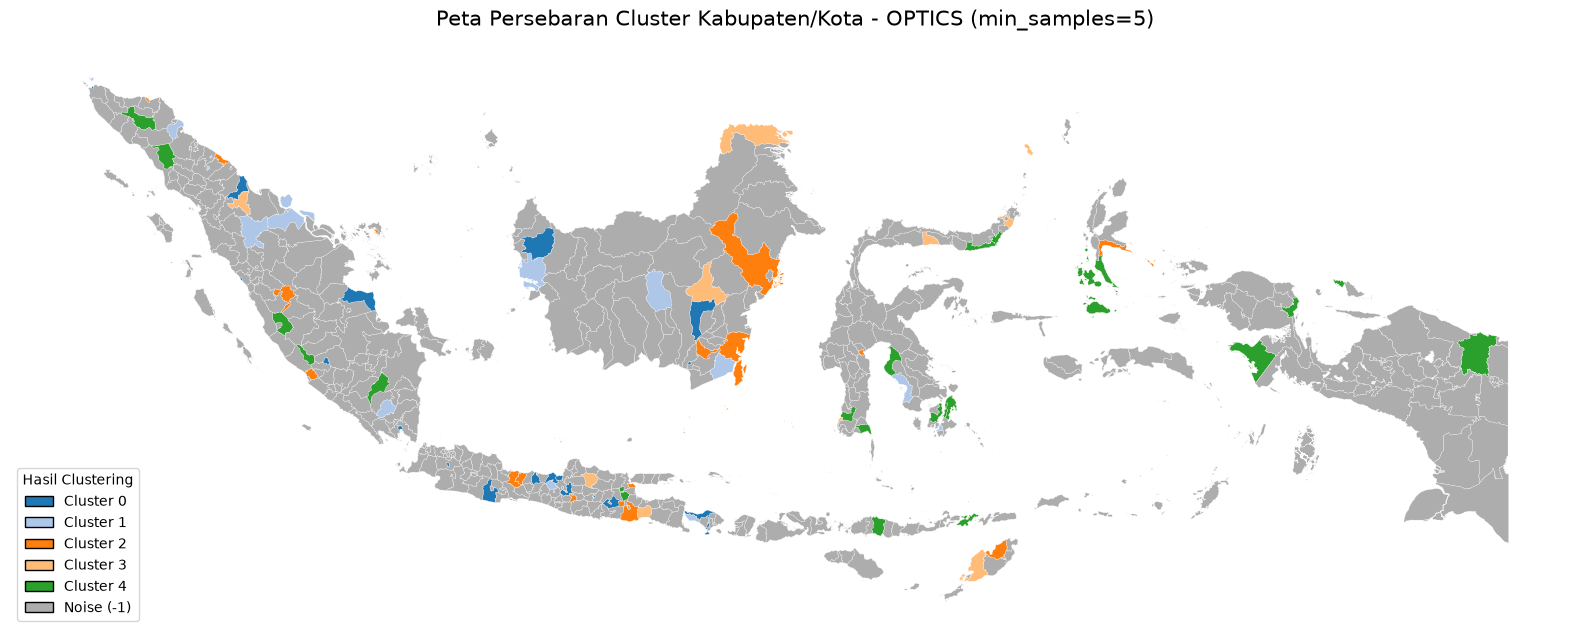

In [77]:
gdf_boundaries, join_keys = load_geojson_boundaries()

gdf_map = build_cluster_map(
    optics_final_output,
    cluster_column="Cluster_OPTICS",
    cluster_label_column="Cluster_OPTICS_Label",
    gdf_boundaries=gdf_boundaries,
    join_keys=join_keys,
)

plot_cluster_choropleth(
    gdf_map,
    label_column="Cluster_OPTICS",
    algorithm_name=f"OPTICS (min_samples={best_optics_min_samples})",
    output_filename="optics_cluster_map.png",
)

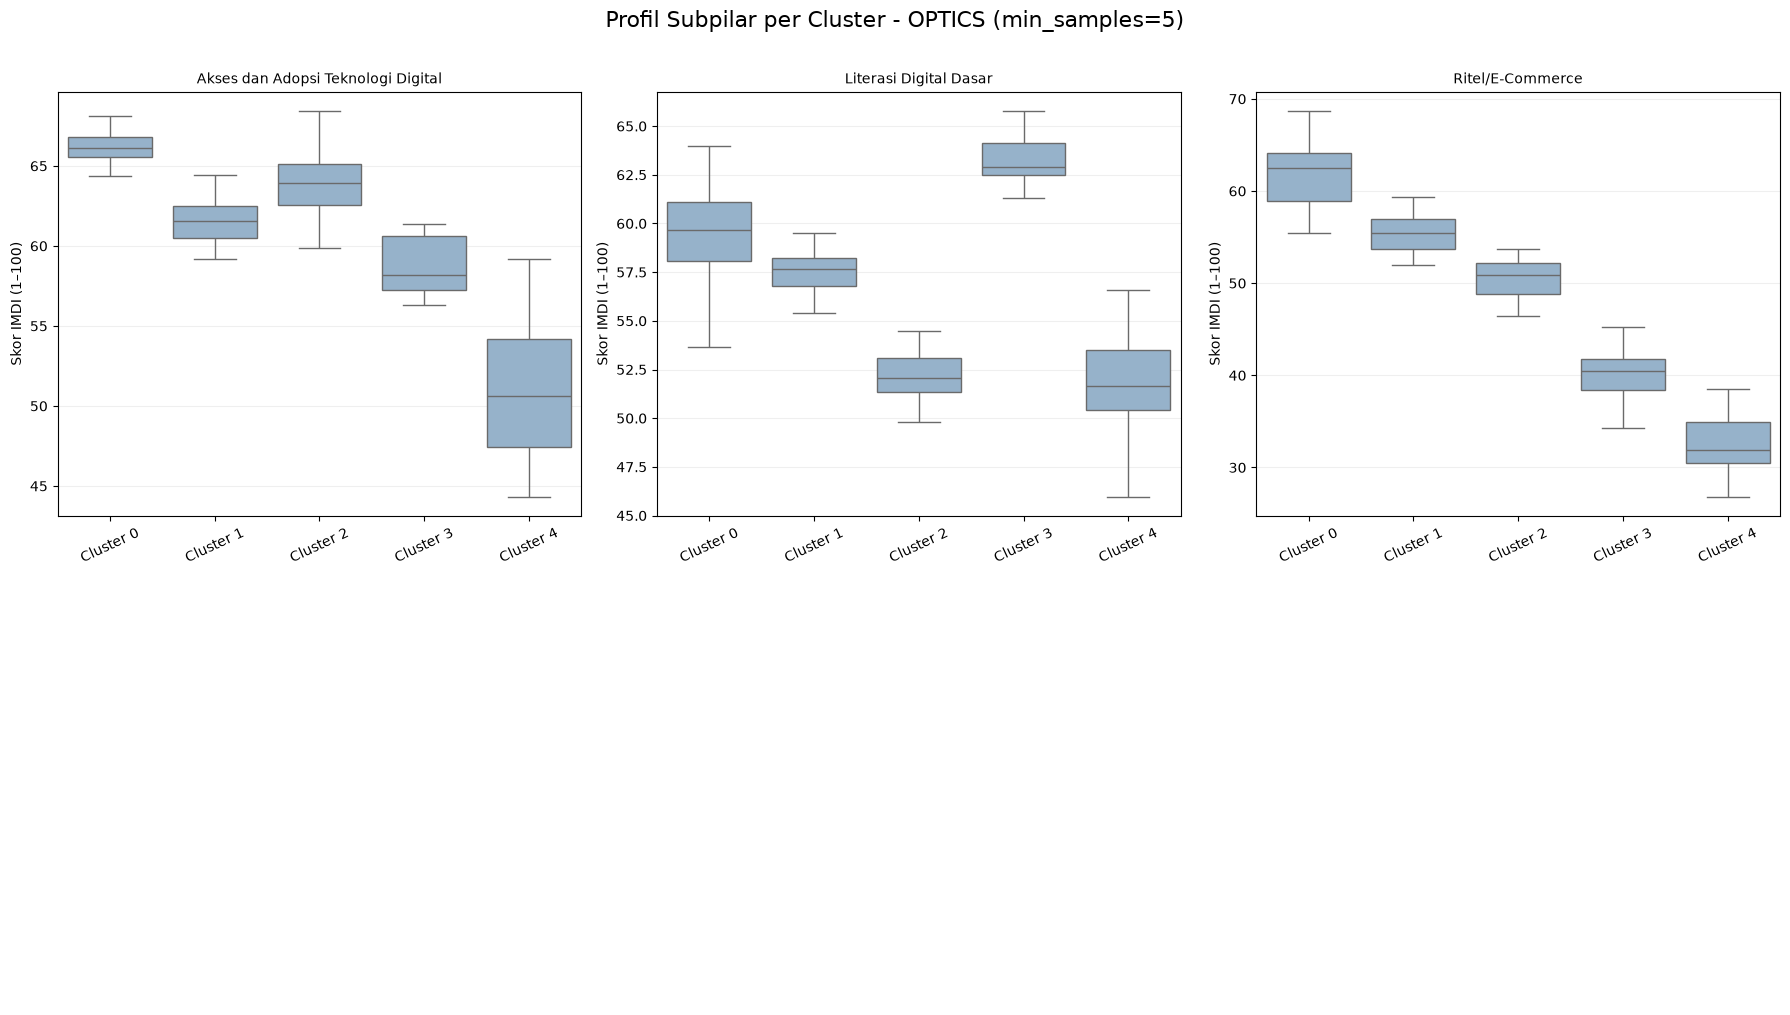

,Akses dan Adopsi Teknologi Digital,Literasi Digital Dasar,Ritel/E-Commerce
cluster_label,,,
Cluster 0,66.09,59.67,62.48
Cluster 1,61.58,57.66,55.46
Cluster 2,63.93,52.06,50.88
Cluster 3,58.15,62.89,40.45
Cluster 4,50.61,51.68,31.88


Jumlah noise OPTICS: 435


In [78]:
## BOXPLOT VISUALIZATION OF CLUSTER PROFILES

plot_cluster_profile_boxplots(
    optics_final_labels,
    algorithm_name=f"OPTICS (min_samples={best_optics_min_samples})",
    output_filename="optics_cluster_profile_boxplots.png",
    include_noise=False,
)

print("Jumlah noise OPTICS:", int(np.sum(optics_final_labels == -1)))

---
## 8. Spectral Clustering Modelling

In [79]:
spectral_experiment_labels = {}
spectral_experiment_models = {}
spectral_rows = []

for k in SPECTRAL_K_LIST:
    print(f"Menjalankan Spectral Clustering n_clusters={k} ...")
    model = SpectralClustering(n_clusters=k, **SPECTRAL_FIXED_PARAMS)
    labels = model.fit_predict(X_cluster)

    spectral_experiment_models[k] = model
    spectral_experiment_labels[k] = labels.copy()

    metric_result = evaluate_cluster_labels(X_cluster, labels, ignore_noise=False)
    cluster_counts = pd.Series(labels).value_counts().sort_index().to_dict()

    spectral_rows.append({
        "jumlah_cluster_diminta": k,
        "jumlah_cluster_aktual": metric_result["n_clusters"],
        "jumlah_observasi": len(labels),
        "silhouette_score": metric_result["silhouette"],
        "davies_bouldin_index": metric_result["davies_bouldin"],
        "ukuran_cluster": {int(key): int(value) for key, value in cluster_counts.items()},
        "status_evaluasi": metric_result["evaluation_status"],
    })

spectral_results = pd.DataFrame(spectral_rows)
display(spectral_results)
spectral_results.to_csv(OUTPUT_DIR / "spectral_experiment_results.csv", index=False)

Menjalankan Spectral Clustering n_clusters=2 ...
Menjalankan Spectral Clustering n_clusters=3 ...
Menjalankan Spectral Clustering n_clusters=4 ...
Menjalankan Spectral Clustering n_clusters=5 ...
Menjalankan Spectral Clustering n_clusters=6 ...
Menjalankan Spectral Clustering n_clusters=7 ...
Menjalankan Spectral Clustering n_clusters=8 ...
Menjalankan Spectral Clustering n_clusters=9 ...
Menjalankan Spectral Clustering n_clusters=10 ...


,jumlah_cluster_diminta,jumlah_cluster_aktual,jumlah_observasi,silhouette_score,davies_bouldin_index,ukuran_cluster,status_evaluasi
0,2,2,514,0.364589,1.130214,"{0: 189, 1: 325}",OK
1,3,3,514,0.252032,1.241610,"{0: 190, 1: 159, 2: 165}",OK
2,4,4,514,0.222808,1.256244,"{0: 127, 1: 173, 2: 129, 3: 85}",OK
3,5,5,514,0.218214,1.175865,"{0: 97, 1: 122, 2: 131, 3: 83, 4: 81}",OK
4,6,6,514,0.189683,1.191557,"{0: 79, 1: 73, 2: 53, 3: 120, 4: 64, 5: 125}",OK
5,7,7,514,0.203806,1.148309,"{0: 84, 1: 111, 2: 53, 3: 113, 4: 50, 5: 82, 6...",OK
6,8,8,514,0.206003,1.152968,"{0: 62, 1: 86, 2: 91, 3: 46, 4: 85, 5: 18, 6: ...",OK
7,9,9,514,0.224631,1.095559,"{0: 76, 1: 89, 2: 39, 3: 67, 4: 45, 5: 55, 6: ...",OK
8,10,10,514,0.229134,1.052731,"{0: 71, 1: 49, 2: 59, 3: 44, 4: 56, 5: 37, 6: ...",OK


In [80]:
spectral_cluster_size_rows = []
for k, labels in spectral_experiment_labels.items():
    counts = pd.Series(labels).value_counts().sort_index()
    for cluster_id, count in counts.items():
        spectral_cluster_size_rows.append({
            "jumlah_cluster_diminta": k,
            "cluster": f"Cluster {cluster_id}",
            "jumlah_kabupaten_kota": int(count),
        })
spectral_cluster_sizes = pd.DataFrame(spectral_cluster_size_rows)
display(spectral_cluster_sizes)
spectral_cluster_sizes.to_csv(OUTPUT_DIR / "spectral_cluster_sizes_all_experiments.csv", index=False)

,jumlah_cluster_diminta,cluster,jumlah_kabupaten_kota
0,2,Cluster 0,189
1,2,Cluster 1,325
2,3,Cluster 0,190
3,3,Cluster 1,159
4,3,Cluster 2,165
5,4,Cluster 0,127
6,4,Cluster 1,173
7,4,Cluster 2,129
8,4,Cluster 3,85
9,5,Cluster 0,97


---
## 9. Spectral Clustering Visualization

In [81]:
if best_spectral_k not in SPECTRAL_K_LIST:
    raise ValueError(
        f"best_spectral_k harus salah satu dari {SPECTRAL_K_LIST}. "
        "Ubah variabel pada cell konfigurasi awal."
    )

final_spectral_model = SpectralClustering(
    n_clusters=best_spectral_k,
    **SPECTRAL_FIXED_PARAMS
)
spectral_final_labels = final_spectral_model.fit_predict(X_cluster)

spectral_final_output = df[METADATA_COLUMNS + [INDEX_COLUMN]].copy()
spectral_final_output["Cluster_Spectral"] = spectral_final_labels
spectral_final_output["Cluster_Spectral_Label"] = [f"Cluster {label}" for label in spectral_final_labels]

display(spectral_final_output.head(10))
print("Konfigurasi final Spectral Clustering:", best_spectral_k)
print("Jumlah cluster aktual:", len(np.unique(spectral_final_labels)))
spectral_final_output.to_csv(OUTPUT_DIR / "spectral_final_cluster_assignments.csv", index=False)

,Tahun,Kode Provinsi,Provinsi,Kode Kabupaten/Kota,Kabupaten/Kota,Indeks Masyarakat Digital,Cluster_Spectral,Cluster_Spectral_Label
0,2025,32,JAWA BARAT,71,KOTA BANDUNG,64.767412,1,Cluster 1
1,2025,35,JAWA TIMUR,7,KOTA MALANG,62.670962,1,Cluster 1
2,2025,82,DKI JAKARTA,74,KOTA JAKARTA BARAT,61.581305,1,Cluster 1
3,2025,12,SUMATERA UTARA,75,KOTA MEDAN,59.996021,1,Cluster 1
4,2025,82,DKI JAKARTA,71,KOTA JAKARTA SELATAN,59.925852,1,Cluster 1
5,2025,32,JAWA BARAT,17,BANDUNG BARAT,59.307290,1,Cluster 1
6,2025,35,JAWA TIMUR,4,TULUNGAGUNG,59.288478,1,Cluster 1
7,2025,82,DKI JAKARTA,72,KOTA JAKARTA TIMUR,59.232277,1,Cluster 1
8,2025,33,JAWA TENGAH,4,BANJARNEGARA,58.981221,1,Cluster 1
9,2025,33,JAWA TENGAH,22,KOTA SEMARANG,58.588099,1,Cluster 1


Konfigurasi final Spectral Clustering: 2
Jumlah cluster aktual: 2


GeoJSON berhasil diunduh dari URL (17,667,144 bytes)
Fitur geometri GeoJSON              : 514
Wilayah berhasil dipasangkan        : 514
Fitur GeoJSON tidak cocok           : 0
Wilayah IMDI belum punya geometri   : 0


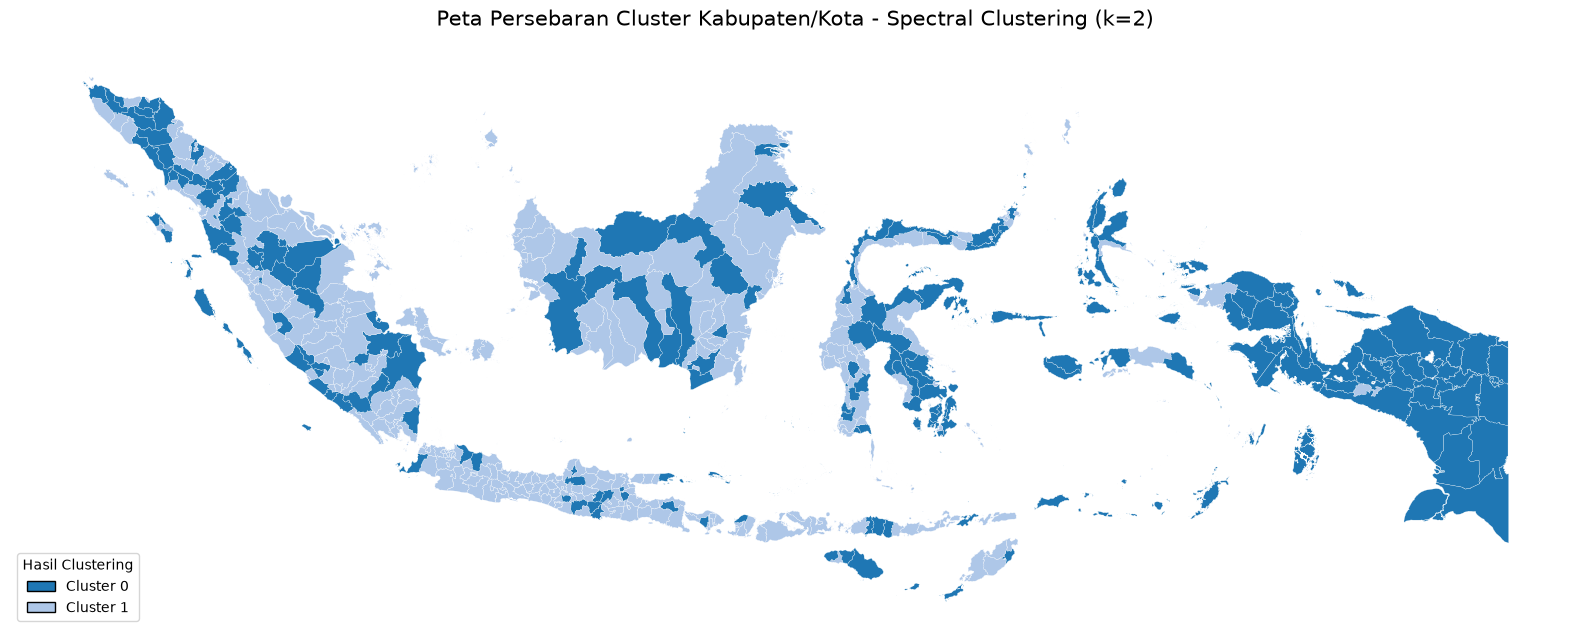

In [82]:
gdf_boundaries, join_keys = load_geojson_boundaries()

gdf_map = build_cluster_map(
    spectral_final_output,
    cluster_column="Cluster_Spectral",
    cluster_label_column="Cluster_Spectral_Label",
    gdf_boundaries=gdf_boundaries,
    join_keys=join_keys,
)

plot_cluster_choropleth(
    gdf_map,
    label_column="Cluster_Spectral",
    algorithm_name=f"Spectral Clustering (k={best_spectral_k})",
    output_filename="spectral_cluster_map.png",
)

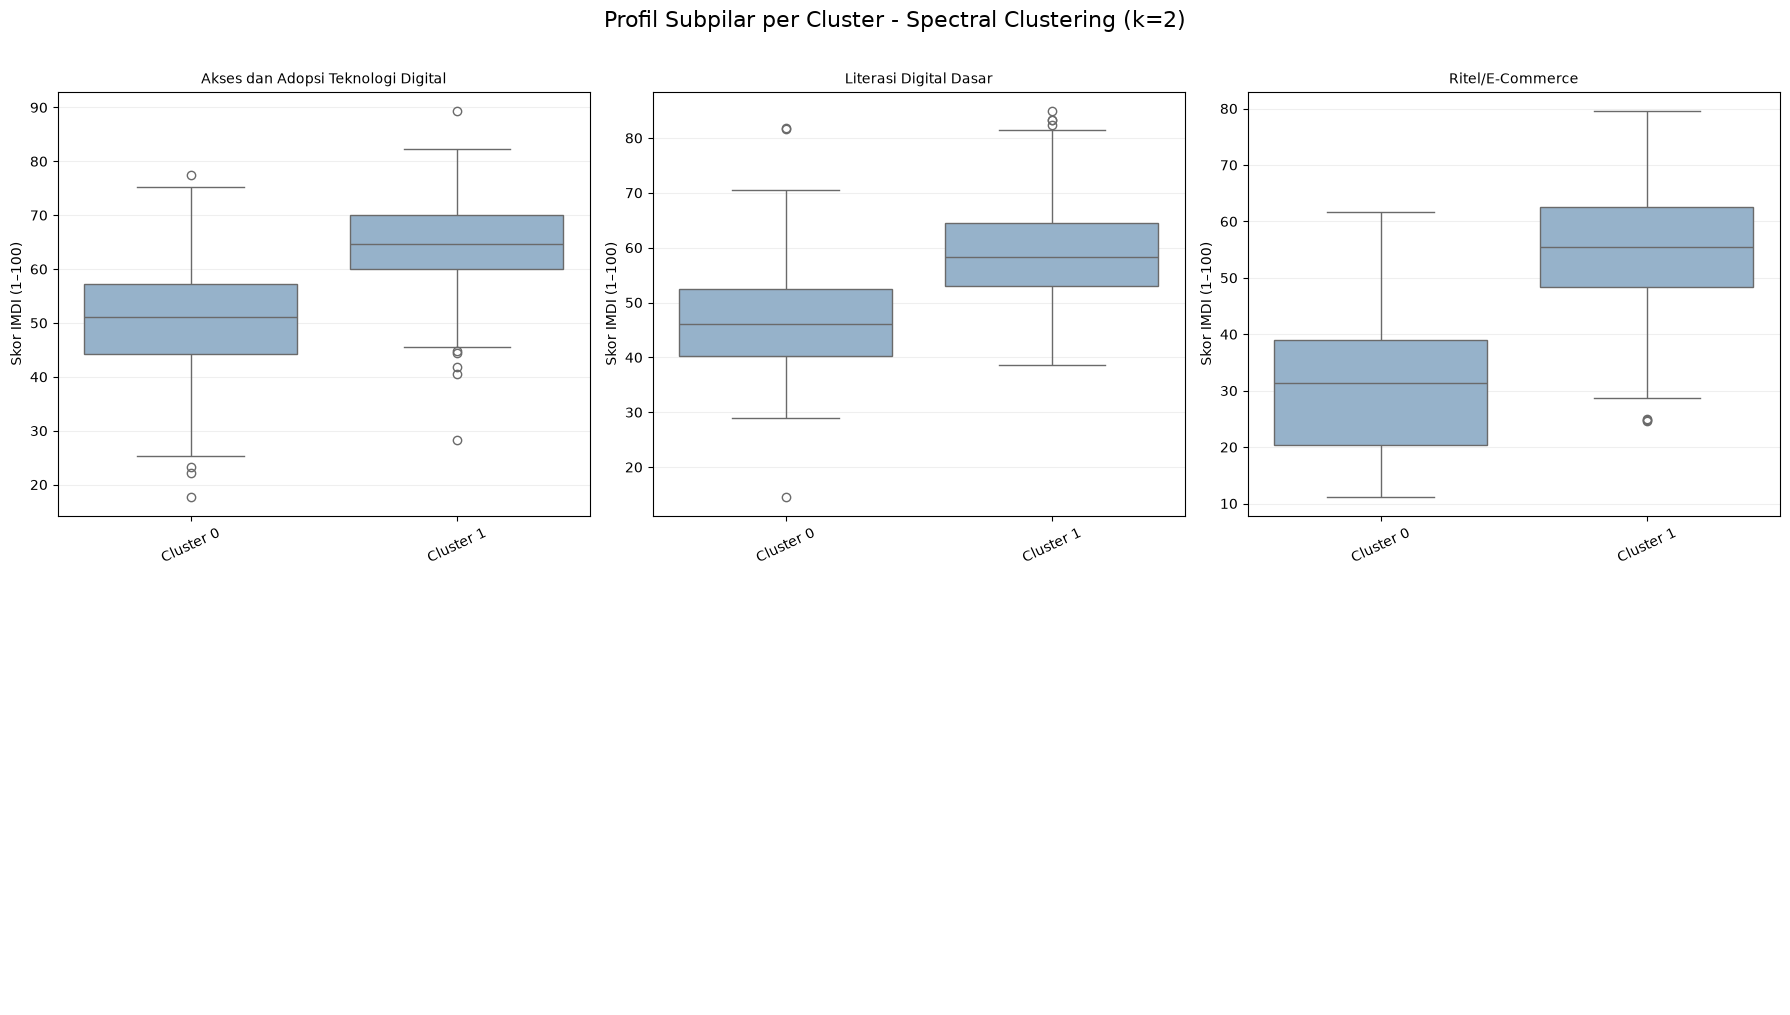

,Akses dan Adopsi Teknologi Digital,Literasi Digital Dasar,Ritel/E-Commerce
cluster_label,,,
Cluster 0,51.05,46.01,31.31
Cluster 1,64.72,58.25,55.38


In [83]:
plot_cluster_profile_boxplots(
    spectral_final_labels,
    algorithm_name=f"Spectral Clustering (k={best_spectral_k})",
    output_filename="spectral_cluster_profile_boxplots.png",
    include_noise=True,
)

---
## 10. OPTICS and Spectral Clustering Comparison Summary

In [84]:
optics_final_metrics = evaluate_cluster_labels(X_cluster, optics_final_labels, ignore_noise=True)
spectral_final_metrics = evaluate_cluster_labels(X_cluster, spectral_final_labels, ignore_noise=False)

final_comparison = pd.DataFrame([
    {
        "algoritma": "OPTICS",
        "konfigurasi": f"min_samples={best_optics_min_samples}",
        "jumlah_cluster": optics_final_metrics["n_clusters"],
        "observasi_dievaluasi": optics_final_metrics["n_evaluated"],
        "noise": int(np.sum(optics_final_labels == -1)),
        "coverage_percent": float(np.mean(optics_final_labels != -1) * 100),
        "silhouette_score": optics_final_metrics["silhouette"],
        "davies_bouldin_index": optics_final_metrics["davies_bouldin"],
    },
    {
        "algoritma": "Spectral Clustering",
        "konfigurasi": f"k={best_spectral_k}",
        "jumlah_cluster": spectral_final_metrics["n_clusters"],
        "observasi_dievaluasi": spectral_final_metrics["n_evaluated"],
        "noise": 0,
        "coverage_percent": 100.0,
        "silhouette_score": spectral_final_metrics["silhouette"],
        "davies_bouldin_index": spectral_final_metrics["davies_bouldin"],
    },
])
display(final_comparison.round(4))
final_comparison.to_csv(OUTPUT_DIR / "final_algorithm_comparison.csv", index=False)

common_mask = np.asarray(optics_final_labels) != -1
common_rows = []
if common_mask.sum() > 0:
    optics_same_subset = evaluate_cluster_labels(X_cluster.loc[common_mask], np.asarray(optics_final_labels)[common_mask])
    spectral_same_subset = evaluate_cluster_labels(X_cluster.loc[common_mask], np.asarray(spectral_final_labels)[common_mask])

    common_rows = [
        {
            "algoritma": "OPTICS",
            "subset": "Observasi non-noise OPTICS",
            "jumlah_observasi": int(common_mask.sum()),
            "jumlah_cluster": optics_same_subset["n_clusters"],
            "silhouette_score": optics_same_subset["silhouette"],
            "davies_bouldin_index": optics_same_subset["davies_bouldin"],
            "status": optics_same_subset["evaluation_status"],
        },
        {
            "algoritma": "Spectral Clustering",
            "subset": "Observasi non-noise OPTICS",
            "jumlah_observasi": int(common_mask.sum()),
            "jumlah_cluster": spectral_same_subset["n_clusters"],
            "silhouette_score": spectral_same_subset["silhouette"],
            "davies_bouldin_index": spectral_same_subset["davies_bouldin"],
            "status": spectral_same_subset["evaluation_status"],
        },
    ]

same_subset_comparison = pd.DataFrame(common_rows)
display(same_subset_comparison.round(4))
same_subset_comparison.to_csv(OUTPUT_DIR / "same_subset_algorithm_comparison.csv", index=False)

,algoritma,konfigurasi,jumlah_cluster,observasi_dievaluasi,noise,coverage_percent,silhouette_score,davies_bouldin_index
0,OPTICS,min_samples=5,5,79,435,15.3696,0.4747,0.7195
1,Spectral Clustering,k=2,2,514,0,100.0000,0.3646,1.1302


,algoritma,subset,jumlah_observasi,jumlah_cluster,silhouette_score,davies_bouldin_index,status
0,OPTICS,Observasi non-noise OPTICS,79,5,0.4747,0.7195,OK
1,Spectral Clustering,Observasi non-noise OPTICS,79,2,0.5576,0.5923,OK


In [85]:
optics_profile = X_raw.copy()
optics_profile["cluster"] = optics_final_labels
optics_profile = optics_profile[optics_profile["cluster"] != -1]
optics_profile_median = optics_profile.groupby("cluster")[SUBPILAR_FEATURES].median().round(2)
optics_profile_median.index = [f"OPTICS Cluster {i}" for i in optics_profile_median.index]

spectral_profile = X_raw.copy()
spectral_profile["cluster"] = spectral_final_labels
spectral_profile_median = spectral_profile.groupby("cluster")[SUBPILAR_FEATURES].median().round(2)
spectral_profile_median.index = [f"Spectral Cluster {i}" for i in spectral_profile_median.index]

combined_profiles = pd.concat([optics_profile_median, spectral_profile_median], axis=0)
display(combined_profiles)
combined_profiles.to_csv(OUTPUT_DIR / "cluster_profile_median_comparison.csv")

,Akses dan Adopsi Teknologi Digital,Literasi Digital Dasar,Ritel/E-Commerce
OPTICS Cluster 0,66.09,59.67,62.48
OPTICS Cluster 1,61.58,57.66,55.46
OPTICS Cluster 2,63.93,52.06,50.88
OPTICS Cluster 3,58.15,62.89,40.45
OPTICS Cluster 4,50.61,51.68,31.88
Spectral Cluster 0,51.05,46.01,31.31
Spectral Cluster 1,64.72,58.25,55.38


---
## 11. Result Export

In [86]:
print("Folder hasil:", OUTPUT_DIR.resolve())
output_files = sorted(p.name for p in OUTPUT_DIR.glob("*") if p.is_file())
display(pd.DataFrame({"file_output": output_files}))

print("\nRingkasan konfigurasi akhir:")
print(f"OPTICS: min_samples={best_optics_min_samples}")
print(f"Spectral Clustering: k={best_spectral_k}")
print(f"Fitur clustering: {len(SUBPILAR_FEATURES)} subpilar")
print("Fitur yang digunakan:", ", ".join(SUBPILAR_FEATURES))
print(f"OPTICS noise: {int(np.sum(optics_final_labels == -1))} dari {len(df)} observasi")

Folder hasil: C:\Users\Valentino\OneDrive - Universitas Tarumanagara\Documents\Kuliah\Semester 7\Machine Learning\Tugas\UAS\Project\outputs


,file_output
0,cluster_profile_median_comparison.csv
1,final_algorithm_comparison.csv
2,iqr_capping_summary.csv
3,optics_cluster_map.png
4,optics_cluster_profile_boxplots.png
5,optics_cluster_profile_boxplots_profile_summar...
6,optics_cluster_sizes_all_experiments.csv
7,optics_experiment_results.csv
8,optics_final_cluster_assignments.csv
9,same_subset_algorithm_comparison.csv



Ringkasan konfigurasi akhir:
OPTICS: min_samples=5
Spectral Clustering: k=2
Fitur clustering: 3 subpilar
Fitur yang digunakan: Akses dan Adopsi Teknologi Digital, Literasi Digital Dasar, Ritel/E-Commerce
OPTICS noise: 435 dari 514 observasi
